# 05 — Verification: do branches in need actually get access?

**The thesis test.** Run the entire loop (pressure → request → allocation) as-of **2025-03**,
then judge every decision against the 12 months that actually happened. Decision-quality
metrics — not forecast metrics:

- **True need**: a unit whose actual next-12-month mean demand exceeded its recent capacity.
- **Recall (detection)**: of all true-need units, how many raised a request? *(a needy branch
  that stays silent never gets access — this is the metric the mission sentence is about)*
- **Precision**: of requested units, how many truly needed it?
- **Access rate**: of true-need units that asked, how many received funding?
- **Coverage**: how much of the true need (in WTE) did granted capacity cover?
- **Policy test**: same budgets, two ranking rules — forecast-driven priority vs "fund the
  biggest current backlog". Does the forecast actually improve where the staff goes?

In [1]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

SLOTS_PER_WTE = 200
AS_OF = "2025-03"  # backtest date: leaves 12 months of actuals to judge against

w = pd.read_csv("../data/processed/ops_panel.csv")
feat = pd.read_csv("../data/processed/features.csv")
saved = torch.load("../data/processed/models_src.pt", weights_only=False)
specs, FEATS = saved["specs"], saved["feats"]
spec_idx = {s: i for i, s in enumerate(specs)}
ser = ["provider_code", "specialty_code"]
months = sorted(w["month"].unique())
trusts = sorted(w["provider_code"].unique())
icb_of = w.drop_duplicates("provider_code").set_index("provider_code")["icb"].to_dict()
device = "cuda" if torch.cuda.is_available() else "cpu"

class Net(nn.Module):
    def __init__(self, emb=4, hidden=32):
        super().__init__()
        self.emb = nn.Embedding(len(specs), emb)
        self.mlp = nn.Sequential(nn.Linear(len(FEATS) + emb, hidden), nn.ReLU(),
                                 nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, 1))
    def forward(self, x, s):
        return x[:, 0] + self.mlp(torch.cat([x, self.emb(s)], dim=1)).squeeze(-1)

@torch.no_grad()
def forecast_12m(trust, as_of):  # same rollout as notebook 03
    sub = feat[(feat["provider_code"] == trust) & (feat["month"] <= as_of)]
    hist = sub.pivot(index="month", columns="specialty_code", values="y").sort_index()
    last = sub[sub["month"] == sub["month"].max()].set_index("specialty_code")
    cols = list(hist.columns)
    mu, sd = last["mu"].reindex(cols).values, last["sd"].reindex(cols).values
    ctx = last[["backlog", "throughput"]].reindex(cols).values
    sidx = torch.tensor([spec_idx[c] for c in cols]).to(device)
    model = Net().to(device)
    model.load_state_dict(saved["fed_ft"][trust])
    model.eval()
    buf = hist.values
    p = pd.Period(as_of, "M")
    preds = []
    for h in range(1, 13):
        tm = p + h
        lag12 = hist.loc[(tm - 12).strftime("%Y-%m")].values
        x = np.column_stack([buf[-1], buf[-2], buf[-3], lag12, ctx[:, 0], ctx[:, 1],
                             np.full(len(cols), np.sin(2 * np.pi * tm.month / 12)),
                             np.full(len(cols), np.cos(2 * np.pi * tm.month / 12))])
        y = model(torch.tensor(x, dtype=torch.float32).to(device), sidx).cpu().numpy()
        buf = np.vstack([buf, y])
        preds.append(np.expm1(y * sd + mu))
    return pd.DataFrame(np.array(preds), columns=cols)

def make_requests(as_of):  # same rule as notebook 03
    upto = [m for m in months if m <= as_of]
    red2 = w[w["month"].isin(upto[-3:])].groupby(ser)["red"].sum() >= 2
    thr6 = w[w["month"].isin(upto[-6:])].groupby(ser)["throughput"].mean()
    snap = w[w["month"] == as_of].set_index(ser)
    rows = []
    for t in trusts:
        fc = forecast_12m(t, as_of)
        for spec in fc.columns:
            if not red2.get((t, spec), False):
                continue
            gap = fc[spec].mean() - thr6[(t, spec)]
            if gap <= 0:
                continue
            rows.append({"provider_code": t, "specialty_code": spec, "icb": icb_of[t],
                         "gap": round(gap), "backlog_now": snap.loc[(t, spec), "backlog"],
                         "fc_mean": fc[spec].mean(), "last_demand": snap.loc[(t, spec), "demand"],
                         "priority": gap * (1 + snap.loc[(t, spec), "share52"])})
    return pd.DataFrame(rows)

def allocate(requests, as_of, rank_col, budget_pct=0.02):  # generic: rank by any column
    thr6 = w[w["month"].isin([m for m in months if m <= as_of][-6:])] \
        .groupby("provider_code")["throughput"].sum() / 6
    budgets = {icb: budget_pct * sum(thr6[t] for t in trusts if icb_of[t] == icb)
               for icb in set(icb_of.values())}
    out = []
    for _, r in requests.sort_values(rank_col, ascending=False).iterrows():
        grant = min(r["gap"], budgets[r["icb"]])
        budgets[r["icb"]] -= grant
        out.append({**r, "granted": round(grant)})
    return pd.DataFrame(out)

req = make_requests(AS_OF)
print(f"backtest as-of {AS_OF}: {len(req)} requests raised")

backtest as-of 2025-03: 451 requests raised


In [2]:
# ground truth: TRUE NEED over the 12 months after AS_OF, for EVERY unit (not just requesters)
future = w[w["month"] > AS_OF]
actual12 = future.groupby(ser)["demand"].mean()
thr6 = w[w["month"].isin([m for m in months if m <= AS_OF][-6:])].groupby(ser)["throughput"].mean()
need = (actual12 - thr6).clip(lower=0)
need_units = set(need[need > 0].index)
req_units = set(zip(req["provider_code"], req["specialty_code"]))

tp = need_units & req_units
recall = len(tp) / len(need_units)
precision = len(tp) / len(req_units)
print(f"true-need units: {len(need_units)} of {len(need)} | requests: {len(req_units)}")
print(f"DETECTION recall:  {recall:.0%}  (needy units that raised a request)")
print(f"REQUEST precision: {precision:.0%}  (requests that were truly needed)")

# access: of needy units that asked, who got funding — and how much of the need it covered
alloc = allocate(req, AS_OF, "priority")
alloc["unit"] = list(zip(alloc["provider_code"], alloc["specialty_code"]))
funded_needy = alloc[(alloc["granted"] > 0) & (alloc["unit"].isin(need_units))]
asked_needy = alloc[alloc["unit"].isin(need_units)]
access = len(funded_needy) / len(asked_needy)
useful = sum(min(g, need[u]) for g, u in zip(alloc["granted"], alloc["unit"]))
coverage = useful / need[list(need_units)].sum()
print(f"ACCESS rate:       {access:.0%}  (needy requesters that received funding)")
print(f"NEED coverage:     {coverage:.1%} of total true need ({need[list(need_units)].sum() / SLOTS_PER_WTE:,.0f} WTE) "
      f"covered under the 2% budget")

# the misses matter most: largest true needs that raised NO request (silent shortfalls)
missed = need[list(need_units - req_units)].sort_values(ascending=False)
print(f"\nlargest SILENT needs (no request raised) — {len(missed)} units, "
      f"{missed.sum() / SLOTS_PER_WTE:,.0f} WTE undetected:")
print((missed.head(8) / SLOTS_PER_WTE).round(1).rename("WTE").to_string())

true-need units: 519 of 694 | requests: 451
DETECTION recall:  82%  (needy units that raised a request)
REQUEST precision: 95%  (requests that were truly needed)
ACCESS rate:       10%  (needy requesters that received funding)
NEED coverage:     8.1% of total true need (646 WTE) covered under the 2% budget

largest SILENT needs (no request raised) — 92 units, 37 WTE undetected:
provider_code  specialty_code
RR8            C_320             2.1
RRK            C_130             1.7
RHM            C_330             1.7
RM3            C_502             1.6
R0D            X06               1.2
REM            X06               1.2
RTH            X05               1.1
RTE            X06               1.0


                          granted     useful  useful_share  need_coverage
policy                                                                   
forecast-driven priority    11712  10424.750          0.89          0.081
biggest current backlog     11712   9724.167          0.83          0.075

12-month-mean demand MAE on requested units: federated 117 vs naive 106 referrals


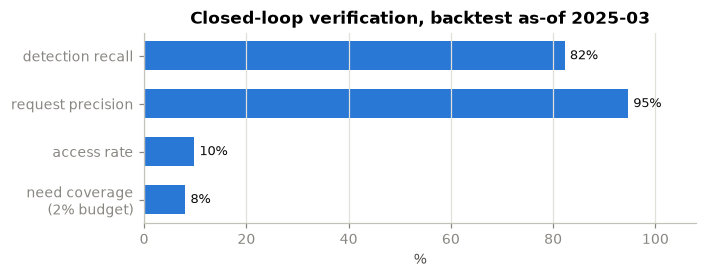

In [3]:
# does the forecast improve WHERE staff goes? same budgets, two ranking rules
import matplotlib.pyplot as plt
policies = {"forecast-driven priority": "priority", "biggest current backlog": "backlog_now"}
rows = []
for name, col in policies.items():
    a = allocate(req, AS_OF, col)
    a["unit"] = list(zip(a["provider_code"], a["specialty_code"]))
    useful = sum(min(g, need[u]) for g, u in zip(a["granted"], a["unit"]))
    rows.append({"policy": name, "granted": a["granted"].sum(),
                 "useful": useful, "useful_share": useful / a["granted"].sum(),
                 "need_coverage": useful / need[list(need_units)].sum()})
pol = pd.DataFrame(rows).set_index("policy")
print(pol.round(3).to_string())

# forecast-vs-naive on requested units (continuity with the known weak spot)
actual = np.array([actual12[u] for u in zip(req["provider_code"], req["specialty_code"])])
print(f"\n12-month-mean demand MAE on requested units: "
      f"federated {np.abs(req['fc_mean'].values - actual).mean():.0f} vs "
      f"naive {np.abs(req['last_demand'].values - actual).mean():.0f} referrals")

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "axes.labelcolor": "#52514e", "xtick.color": "#898781", "ytick.color": "#898781",
})
fig, ax = plt.subplots(figsize=(6.5, 2.6))
vals = [recall, precision, access, coverage]
names = ["detection recall", "request precision", "access rate", "need coverage\n(2% budget)"]
bars = ax.barh(names[::-1], [v * 100 for v in vals[::-1]], color="#2a78d6", height=0.6)
for i, v in enumerate(vals[::-1]):
    ax.text(v * 100 + 1, i, f"{v:.0%}", va="center", fontsize=8.5, color="#0b0b0b")
ax.set_title(f"Closed-loop verification, backtest as-of {AS_OF}")
ax.set_xlabel("%")
ax.set_xlim(0, 108)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()